In [1]:
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
G = nx.Graph()

roads = [
    ("A", "B", 4),
    ("A", "C", 3),
    ("B", "D", 5),
    ("B", "E", 2),
    ("C", "E", 4),
    ("C", "G", 6),
    ("D", "F", 3),
    ("F", "G", 2)
]

G.add_weighted_edges_from(roads)

print("Junctions:", list(G.nodes()))
print("Roads:", list(G.edges(data=True)))

Junctions: ['A', 'B', 'C', 'D', 'E', 'G', 'F']
Roads: [('A', 'B', {'weight': 4}), ('A', 'C', {'weight': 3}), ('B', 'D', {'weight': 5}), ('B', 'E', {'weight': 2}), ('C', 'E', {'weight': 4}), ('C', 'G', {'weight': 6}), ('D', 'F', {'weight': 3}), ('G', 'F', {'weight': 2})]


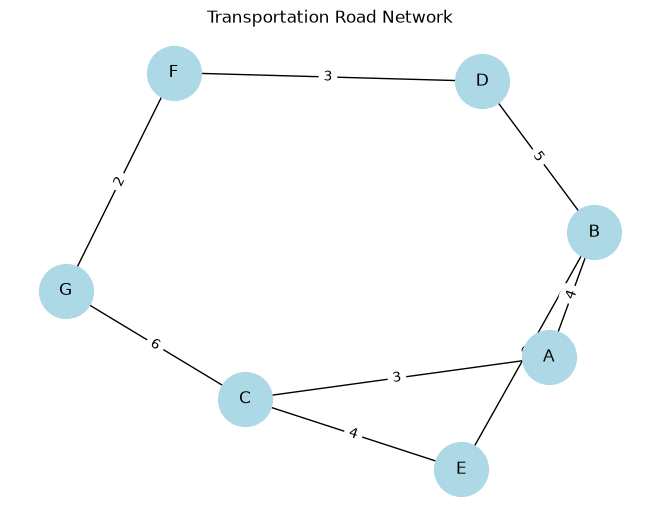

In [3]:
pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_color="lightblue",
    node_size=1500,
    font_size=12
)

labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

plt.title("Transportation Road Network")
plt.show()

In [4]:
source = "A"
destination = "F"

path = nx.shortest_path(G, source, destination, weight="weight")
distance = nx.shortest_path_length(G, source, destination, weight="weight")

print("Shortest Route:", " -> ".join(path))
print("Total Distance:", distance, "km")

Shortest Route: A -> C -> G -> F
Total Distance: 11 km


In [5]:
print("Is the network connected?", nx.is_connected(G))

print("Can A reach G?", nx.has_path(G, "A", "G"))

print("Number of junctions:", G.number_of_nodes())
print("Number of roads:", G.number_of_edges())

Is the network connected? True
Can A reach G? True
Number of junctions: 7
Number of roads: 8


In [6]:
G.remove_edge("C", "G")

print("Road C-G closed due to an accident")

new_path = nx.shortest_path(G, "A", "F", weight="weight")
new_distance = nx.shortest_path_length(G, "A", "F", weight="weight")

print("Alternative Route:", " -> ".join(new_path))
print("New Distance:", new_distance, "km")

Road C-G closed due to an accident
Alternative Route: A -> B -> D -> F
New Distance: 12 km


In [7]:
G.add_edge("C", "G", weight=6)

print("Road C-G restored")
print("Total roads:", G.number_of_edges())

Road C-G restored
Total roads: 8
